# GRU collision monitor for frozen TF++

Trains a small GRU on the windows built by `src/build_monitor_dataset.py` (60 steps × 43 features, label = collision within 3 s) and evaluates it on held-out routes.

- **Window-level:** AUROC (all steps and moving-only), AUPRC, precision / recall / F1.
- **Event-level:** share of collisions warned ≥1 s and ≥2 s ahead at a fixed number of false alarms per minute (1-s blocks of normal driving with an alarm), plus warning lead time.
- **Reference:** a speed-only logistic regression, the baseline that matched most of the signal in `docs/TFpp_failure_analysis.pdf`.

Thresholds are always chosen on **val** and applied unchanged to **test**. Train windows are subsampled (hard negatives every 5 steps, others sparser); val/test keep every window, so their alarm rates reflect real driving.

## 1. Setup

In [1]:
import csv, json, math, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_fscore_support, roc_auc_score
import matplotlib.pyplot as plt

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA = REPO / "data" / "monitor_dataset"
OUT = REPO / "results" / "gru_monitor"
OUT.mkdir(parents=True, exist_ok=True)

CFG = dict(
    hidden=64, layers=1, dropout=0.2,
    lr=1e-3, weight_decay=1e-4, batch_size=256,
    max_epochs=60, patience=8,          # early stopping on val AUPRC
    seeds=[0, 1, 2],
    fa_targets=[1.0, 3.0, 10.0],        # false alarms per minute of normal driving
    dt=0.05,
)
torch.set_num_threads(4)
DEVICE = "cpu"
print(REPO, torch.__version__)

/Users/hassaanmuzammil/Desktop/Repos/Commit-Or-Recover 2.2.2


## 2. Load data

In [2]:
meta = json.loads((DATA / "meta.json").read_text())
FEATURES = meta["feature_names"]
with (DATA / "windows.csv").open() as fh:
    WINDOWS = {int(r["window_id"]): r for r in csv.DictReader(fh)}

def load_split(name):
    d = np.load(DATA / f"{name}.npz")
    rows = [WINDOWS[int(i)] for i in d["window_id"]]
    return dict(X=d["X"].astype(np.float32), y=d["y"].astype(np.float32), ids=d["window_id"], rows=rows)

S = {name: load_split(name) for name in ("train", "val", "test")}
for name, s in S.items():
    n_events = len({(r["run"], r["route_id"], r["seed"]) for r in s["rows"] if r["label"] == "1"})
    print(f"{name:5s} X={s['X'].shape}  positive windows={int(s['y'].sum()):5d} ({s['y'].mean():.1%})  collision events={n_events}")

train X=(6273, 60, 43)  positive windows= 1995 (31.8%)  collision events=38
val   X=(13892, 60, 43)  positive windows=  360 (2.6%)  collision events=8
test  X=(10238, 60, 43)  positive windows=  349 (3.4%)  collision events=8


## 3. Normalize with training statistics only

In [3]:
flat = S["train"]["X"].reshape(-1, S["train"]["X"].shape[-1])
MEAN, STD = flat.mean(0), flat.std(0)
STD[STD < 1e-6] = 1.0
for s in S.values():
    s["Xn"] = (s["X"] - MEAN) / STD
SPEED = FEATURES.index("ego_speed")

## 4. Model

In [4]:
class GRUMonitor(nn.Module):
    def __init__(self, n_features, hidden, layers, dropout):
        super().__init__()
        self.gru = nn.GRU(n_features, hidden, num_layers=layers, batch_first=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):                 # x: [B, T, F]
        _, h = self.gru(x)                # h: [layers, B, hidden]
        return self.head(self.drop(h[-1])).squeeze(-1)   # logits [B]

@torch.no_grad()
def predict(model, X, batch=2048):
    model.eval()
    out = [torch.sigmoid(model(torch.from_numpy(X[i:i + batch]))).numpy() for i in range(0, len(X), batch)]
    return np.concatenate(out)

print(GRUMonitor(len(FEATURES), CFG["hidden"], CFG["layers"], CFG["dropout"]))
print("parameters:", sum(p.numel() for p in GRUMonitor(len(FEATURES), CFG["hidden"], CFG["layers"], CFG["dropout"]).parameters()))

GRUMonitor(
  (gru): GRU(43, 64, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=64, out_features=1, bias=True)
)
parameters: 20993


## 5. Train (weighted BCE + early stopping on val AUPRC)

In [5]:
def train_one(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = GRUMonitor(len(FEATURES), CFG["hidden"], CFG["layers"], CFG["dropout"])
    y = S["train"]["y"]
    pos_weight = torch.tensor((len(y) - y.sum()) / y.sum())        # class imbalance
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    Xt, yt = torch.from_numpy(S["train"]["Xn"]), torch.from_numpy(y)

    best, best_state, bad, history = -1.0, None, 0, []
    for epoch in range(CFG["max_epochs"]):
        model.train()
        perm = torch.randperm(len(Xt))
        total = 0.0
        for i in range(0, len(perm), CFG["batch_size"]):
            idx = perm[i:i + CFG["batch_size"]]
            opt.zero_grad()
            loss = loss_fn(model(Xt[idx]), yt[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(idx)
        val_auprc = average_precision_score(S["val"]["y"], predict(model, S["val"]["Xn"]))
        history.append((total / len(Xt), val_auprc))
        if val_auprc > best:
            best, bad = val_auprc, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]:
                break
    model.load_state_dict(best_state)
    return model, history, best

MODELS, HISTORIES = {}, {}
for seed in CFG["seeds"]:
    t0 = time.time()
    MODELS[seed], HISTORIES[seed], best = train_one(seed)
    print(f"seed {seed}: {len(HISTORIES[seed])} epochs, best val AUPRC {best:.3f}, {time.time() - t0:.0f}s")

seed 0: 15 epochs, best val AUPRC 0.266, 37s


seed 1: 10 epochs, best val AUPRC 0.238, 23s


seed 2: 16 epochs, best val AUPRC 0.262, 53s


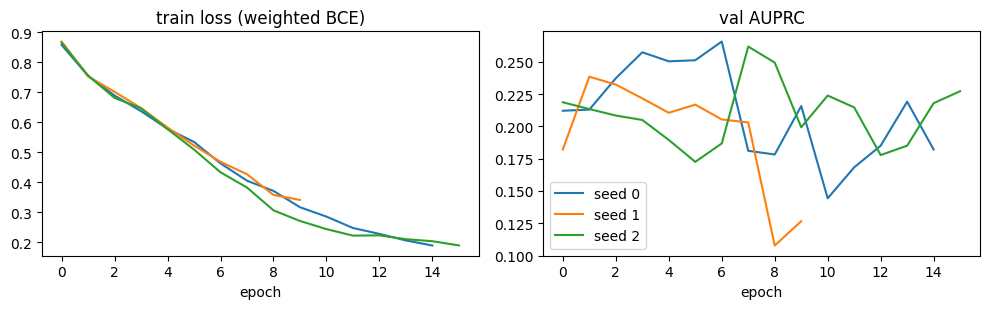

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for seed, h in HISTORIES.items():
    axes[0].plot([a for a, _ in h], label=f"seed {seed}")
    axes[1].plot([b for _, b in h], label=f"seed {seed}")
axes[0].set(title="train loss (weighted BCE)", xlabel="epoch")
axes[1].set(title="val AUPRC", xlabel="epoch")
axes[1].legend()
plt.tight_layout(); fig.savefig(OUT / "training_curves.png", dpi=120); plt.show()

## 6. Speed-only reference

In [7]:
speed_lr = LogisticRegression(class_weight="balanced").fit(S["train"]["Xn"][:, -1, [SPEED]], S["train"]["y"])
def predict_speed(X):
    return speed_lr.predict_proba(X[:, -1, [SPEED]])[:, 1]

## 7. Evaluation code

**Event-level definitions** (val/test are dense, so consecutive windows in a run are consecutive 50 ms steps):
- *Collision event*: the first collision of a run (later windows were dropped by the dataset builder).
- *Alarm*: window probability ≥ threshold.
- *Warned ≥ k s*: some alarm fires on a window whose time-to-collision is between k s and 3 s.
- *Lead time*: time-to-collision of the earliest alarm within the 3 s horizon.
- *False alarms per minute*: number of 1-second blocks of normal driving that contain at least one alarm, divided by minutes of normal driving. An always-on alarm scores 60/min, so it cannot look cheap. Windows 3–6 s before a collision (`pre_failure_buffer`) are excluded from both counts.
- *Warnable*: an event with at least one window ≥1 s before the collision. Collisions in the first ~4 s of a route have no full 3 s history that early, so no model can warn them ≥1 s ahead.

In [8]:
def split_index(s):
    rows = s["rows"]
    run = [(r["run"], r["route_id"], r["seed"]) for r in rows]
    step = np.array([int(r["end_step"]) for r in rows])
    order = np.lexsort((step, np.array([hash(k) for k in run])))
    run_o = [run[i] for i in order]
    same_prev = np.array([i > 0 and run_o[i] == run_o[i - 1] and step[order[i]] == step[order[i - 1]] + 1
                          for i in range(len(order))])
    label = s["y"][order].astype(bool)
    ttc = np.array([float(rows[i]["time_to_collision"]) if rows[i]["time_to_collision"] else np.nan for i in order])
    buffer = np.array([rows[i]["pre_failure_buffer"] == "True" for i in order])
    moving = np.array([rows[i]["moving"] == "True" for i in order])
    codes = {k: n for n, k in enumerate(dict.fromkeys(run_o))}
    second_bin = np.array([codes[run_o[j]] * 1_000_000 + step[i] // 20 for j, i in enumerate(order)])
    events = {}
    for j, i in enumerate(order):
        if label[j]:
            events.setdefault(run_o[j], []).append(j)
    return dict(order=order, same_prev=same_prev, second_bin=second_bin, label=label, ttc=ttc, normal=~label & ~buffer,
                moving=moving, events=list(events.values()),
                minutes=(~label & ~buffer).sum() * CFG["dt"] / 60)

IDX = {name: split_index(S[name]) for name in ("val", "test")}

def fa_per_min(p_sorted, thr, ix):
    alarm = (p_sorted >= thr) & ix["normal"]
    return len(np.unique(ix["second_bin"][alarm])) / ix["minutes"]

def event_stats(p_sorted, thr, ix):
    warned1, warned2, leads, warnable = [], [], [], 0
    for ev in ix["events"]:
        ev = np.array(ev)
        hit = p_sorted[ev] >= thr
        t = ix["ttc"][ev]
        warnable += bool((t >= 1.0).any())
        warned1.append(bool((hit & (t >= 1.0)).any()))
        warned2.append(bool((hit & (t >= 2.0)).any()))
        leads.append(float(t[hit].max()) if hit.any() else np.nan)
    return dict(recall_1s=float(np.mean(warned1)), recall_2s=float(np.mean(warned2)),
                median_lead_s=float(np.nanmedian(leads)) if np.isfinite(leads).any() else float("nan"),
                n_events=len(ix["events"]), n_warnable_1s=warnable)

def threshold_for_fa(p_sorted, ix, target):
    # lowest threshold (most sensitive) whose false-alarm rate is <= target
    for thr in np.unique(np.quantile(p_sorted, np.linspace(0, 1, 1001))):
        if fa_per_min(p_sorted, thr, ix) <= target:
            return float(thr)
    return 1.0

def evaluate(predict_fn, name):
    pv = predict_fn(S["val"]["Xn"])[IDX["val"]["order"]]
    pt = predict_fn(S["test"]["Xn"])[IDX["test"]["order"]]
    iv, it = IDX["val"], IDX["test"]
    yt = it["label"]
    res = dict(model=name,
               auroc=roc_auc_score(yt, pt),
               auroc_moving=roc_auc_score(yt[it["moving"]], pt[it["moving"]]),
               auprc=average_precision_score(yt, pt),
               base_rate=float(yt.mean()))
    # window-level P/R/F1 at the threshold that maximizes F1 on val
    cand = np.unique(np.quantile(pv, np.linspace(0, 1, 501)))
    f1s = [precision_recall_fscore_support(iv["label"], pv >= c, average="binary", zero_division=0)[2] for c in cand]
    thr = float(cand[int(np.argmax(f1s))])
    p, r, f, _ = precision_recall_fscore_support(yt, pt >= thr, average="binary", zero_division=0)
    res.update(f1_threshold=thr, precision=p, recall=r, f1=f, fa_per_min_at_f1_thr=fa_per_min(pt, thr, it))
    # event-level at fixed false alarms per minute (threshold from val)
    for target in CFG["fa_targets"]:
        thr_fa = threshold_for_fa(pv, iv, target)
        ev = event_stats(pt, thr_fa, it)
        res[f"@{target:g}/min"] = dict(threshold=thr_fa, test_fa_per_min=fa_per_min(pt, thr_fa, it), **ev)
    return res, pt

## 8. Results on held-out test routes

In [9]:
RESULTS, TEST_PROBS = [], {}
for seed, model in MODELS.items():
    res, TEST_PROBS[f"gru_seed{seed}"] = evaluate(lambda X, m=model: predict(m, X), f"GRU seed {seed}")
    RESULTS.append(res)
res, TEST_PROBS["speed_only"] = evaluate(predict_speed, "speed-only logreg")
RESULTS.append(res)

def show(results):
    head = f"{'model':18s} {'AUROC':>6s} {'mov.':>6s} {'AUPRC':>6s} {'P':>5s} {'R':>5s} {'F1':>5s}"
    for t in CFG["fa_targets"]:
        head += f" | @{t:g}/min ≥1s ≥2s lead"
    print(head)
    for r in results:
        line = (f"{r['model']:18s} {r['auroc']:6.3f} {r['auroc_moving']:6.3f} {r['auprc']:6.3f} "
                f"{r['precision']:5.2f} {r['recall']:5.2f} {r['f1']:5.2f}")
        for t in CFG["fa_targets"]:
            e = r[f"@{t:g}/min"]
            line += f" | {'':8s}{e['recall_1s']:4.0%} {e['recall_2s']:4.0%} {e['median_lead_s']:4.1f}s"
        print(line)

show(RESULTS)
gru = [r for r in RESULTS if r["model"].startswith("GRU")]
print("\nGRU mean ± std over seeds:")
for k in ("auroc", "auroc_moving", "auprc", "f1"):
    v = [r[k] for r in gru]
    print(f"  {k:13s} {np.mean(v):.3f} ± {np.std(v):.3f}")
for t in CFG["fa_targets"]:
    v1 = [r[f"@{t:g}/min"]["recall_1s"] for r in gru]
    print(f"  recall≥1s @{t:g}/min  {np.mean(v1):.0%} ± {np.std(v1):.0%}")
print(f"\ntest: {IDX['test']['minutes']:.1f} min of normal driving, {len(IDX['test']['events'])} collision events "
      f"({RESULTS[0]['@1/min']['n_warnable_1s']} warnable ≥1 s ahead), "
      f"positive-window base rate {RESULTS[0]['base_rate']:.1%}")

model               AUROC   mov.  AUPRC     P     R    F1 | @1/min ≥1s ≥2s lead | @3/min ≥1s ≥2s lead | @10/min ≥1s ≥2s lead
GRU seed 0          0.596  0.667  0.050  0.04  0.27  0.07 |          12%   0%  0.5s |          38%  25%  0.8s |          50%  38%  1.4s
GRU seed 1          0.720  0.700  0.068  0.08  0.05  0.06 |           0%   0%  0.3s |          25%  12%  0.8s |          50%  50%  2.0s
GRU seed 2          0.571  0.625  0.049  0.04  0.24  0.07 |          12%   0%  0.4s |          12%  12%  0.4s |          50%  38%  1.6s
speed-only logreg   0.712  0.702  0.089  0.12  0.21  0.15 |          12%   0%  1.1s |          50%  12%  1.4s |          62%  62%  2.1s

GRU mean ± std over seeds:
  auroc         0.629 ± 0.065
  auroc_moving  0.664 ± 0.031
  auprc         0.056 ± 0.009
  f1            0.068 ± 0.004
  recall≥1s @1/min  8% ± 6%
  recall≥1s @3/min  25% ± 10%
  recall≥1s @10/min  50% ± 0%

test: 8.1 min of normal driving, 8 collision events (6 warnable ≥1 s ahead), positive-window b

Precision/recall/F1 use the threshold that maximizes F1 on val. The `@N/min` columns use the threshold that gives N false alarms per minute (1-s blocks of normal driving with an alarm) on val; the false-alarm rate actually measured on test is stored in `metrics.json`.

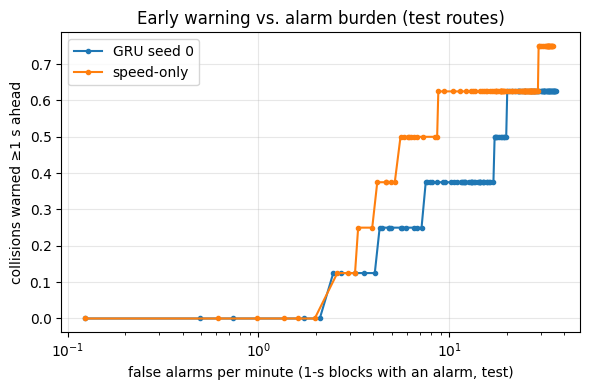

In [10]:
# Warned >=1 s ahead vs. false alarms per minute on test (threshold sweep).
fig, ax = plt.subplots(figsize=(6, 4))
it = IDX["test"]
for name, p in [("GRU seed 0", TEST_PROBS["gru_seed0"]), ("speed-only", TEST_PROBS["speed_only"])]:
    pts = []
    for thr in np.unique(np.quantile(p, np.linspace(0.5, 1, 120))):
        pts.append((fa_per_min(p, thr, it), event_stats(p, thr, it)["recall_1s"]))
    pts.sort()
    ax.plot([a for a, _ in pts], [b for _, b in pts], marker=".", label=name)
ax.set(xscale="log", xlabel="false alarms per minute (1-s blocks with an alarm, test)", ylabel="collisions warned ≥1 s ahead",
       title="Early warning vs. alarm burden (test routes)")
ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); fig.savefig(OUT / "warning_vs_false_alarms.png", dpi=120); plt.show()

## 9. Save model, predictions and metrics

In [11]:
for seed, model in MODELS.items():
    torch.save(dict(state_dict=model.state_dict(), config=CFG, feature_names=FEATURES,
                    mean=MEAN, std=STD, history_steps=meta["history_steps"], horizon_s=meta["horizon_s"]),
               OUT / f"gru_seed{seed}.pt")

order = IDX["test"]["order"]
with (OUT / "test_predictions.csv").open("w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["window_id", "label"] + list(TEST_PROBS))
    for j, i in enumerate(order):
        w.writerow([int(S["test"]["ids"][i]), int(S["test"]["y"][i])] + [f"{TEST_PROBS[k][j]:.5f}" for k in TEST_PROBS])

def to_json(o):
    if isinstance(o, dict): return {k: to_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_json(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
(OUT / "metrics.json").write_text(json.dumps(to_json(dict(
    config=CFG, dataset=str(DATA), results=RESULTS,
    test_minutes_normal_driving=IDX["test"]["minutes"], test_events=len(IDX["test"]["events"]),
    train_history={str(k): v for k, v in HISTORIES.items()})), indent=1))
print(sorted(p.name for p in OUT.iterdir()))

['gru_seed0.pt', 'gru_seed1.pt', 'gru_seed2.pt', 'metrics.json', 'test_predictions.csv', 'training_curves.png', 'warning_vs_false_alarms.png']


## 10. Reading the results

- Test has only a handful of collision events (see the count above), so one event changes event recall by more than 10 points. Treat differences between models as noise unless they are large and hold across all three seeds.
- The GRU only adds value if it beats the **speed-only** row on moving-only AUROC and on event recall at the same false-alarm rate.
- For tighter estimates, rerun with grouped cross-validation over routes or add the seed 200/300 runs to the dataset.